# 01. Análise exploratória da base de avaliações

**Universidade Presbiteriana Mackenzie** · Tecnologia em Banco de Dados · Projeto Aplicado II  
**Grupo Drop Table:** Igor Eduardo Dallan do Couto (RA 10748144), Jaqueline de Oliveira Alves (RA 10755023), Kayo Oliveira Nukui (RA 10356420) e Lucas de Lima Mendes (RA 10756562)  
**Empresa fictícia:** ConectaShop  
**Responsável por este notebook:** Igor Eduardo Dallan do Couto

Antes de treinar qualquer modelo, precisamos conhecer os dados: quantas avaliações existem, quais campos vêm vazios, como as notas se distribuem e como os clientes escrevem. Este notebook responde a essas perguntas usando apenas o arquivo `olist_order_reviews_dataset.csv`, que é o escopo definido na Etapa 1.

A limpeza que alimenta os modelos fica no notebook 02 e em `src/preparacao.py`.

## 1. Bibliotecas

| Biblioteca | O que faz | Por que usamos neste notebook |
|---|---|---|
| `pandas` | Estrutura de dados em tabela (DataFrame) e leitura de CSV | Ler o arquivo de avaliações e contar, agrupar e explorar as colunas |
| `numpy` | Operações numéricas vetorizadas | Calcular estatísticas como média, desvio padrão e percentis das notas |
| `matplotlib` | Biblioteca de gráficos de baixo nível | Controlar tamanho, eixos e exibição dos gráficos |
| `seaborn` | Gráficos estatísticos construídos sobre o matplotlib | Gerar os gráficos de distribuição de notas, boxplots e barras |
| `nltk` | Kit de ferramentas de processamento de linguagem natural | Fornecer a lista de stopwords em português usada na contagem de termos |

In [1]:
from pathlib import Path
import re
import unicodedata
from collections import Counter

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Permite rodar o notebook a partir da pasta notebooks/ ou da raiz do projeto
BASE_DIR = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()

plt.style.use("seaborn-v0_8-whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["font.size"] = 10

## 2. Leitura do arquivo

O arquivo bruto fica em `data/raw/` e não é versionado no GitHub (ver `.gitignore`). Se ele não estiver lá, baixe-o do Kaggle, conforme `data/raw/README.md`.

In [2]:
caminho_arquivo = BASE_DIR / "data" / "raw" / "olist_order_reviews_dataset.csv"
if not caminho_arquivo.exists():
    raise FileNotFoundError(f"Arquivo não encontrado: {caminho_arquivo}")

df_reviews = pd.read_csv(caminho_arquivo, low_memory=False)
print(f"Arquivo lido: data/raw/{caminho_arquivo.name}")
print(f"{len(df_reviews):,} linhas e {df_reviews.shape[1]} colunas")

Arquivo lido: data/raw/olist_order_reviews_dataset.csv
99,224 linhas e 7 colunas


### 2.1 Tipos, valores ausentes e chaves

Para cada coluna, olhamos o tipo, quantos valores estão vazios e quantos valores distintos existem. Também verificamos se `review_id` e `order_id` se repetem, porque isso afeta como contamos avaliações e pedidos.

In [3]:
total_linhas = len(df_reviews)
diagnostico = pd.DataFrame({
    "tipo": df_reviews.dtypes.astype(str),
    "ausentes": df_reviews.isna().sum(),
    "ausentes_%": (df_reviews.isna().mean() * 100).round(2),
    "valores_distintos": df_reviews.nunique(),
})
display(diagnostico)

reviews_unicos = df_reviews["review_id"].nunique()
pedidos_unicos = df_reviews["order_id"].nunique()
print(f"review_id distintos: {reviews_unicos:,} ({total_linhas - reviews_unicos:,} linhas com review_id repetido)")
print(f"order_id distintos:  {pedidos_unicos:,} ({total_linhas - pedidos_unicos:,} linhas de pedidos com mais de uma avaliação)")

,tipo,ausentes,ausentes_%,valores_distintos
review_id,str,0,0.00,98410
order_id,str,0,0.00,98673
review_score,int64,0,0.00,5
review_comment_title,str,87656,88.34,4527
review_comment_message,str,58247,58.70,36159
review_creation_date,str,0,0.00,636
review_answer_timestamp,str,0,0.00,98248


review_id distintos: 98,410 (814 linhas com review_id repetido)
order_id distintos:  98,673 (551 linhas de pedidos com mais de uma avaliação)


**Leitura.** Nota e datas estão sempre preenchidas. O título (`review_comment_title`) falta em cerca de 88% das linhas e a mensagem (`review_comment_message`) em cerca de 59%, porque escrever é opcional para o cliente. Algumas avaliações e alguns pedidos aparecem mais de uma vez; isso não atrapalha a análise de texto, que trata cada linha como uma avaliação, mas é bom saber ao interpretar contagens.

## 3. Distribuição das notas

Agrupamos as notas da mesma forma que os modelos vão usar depois:

| Notas | Grupo | Classe de sentimento |
|---|---|---|
| 4 e 5 | Satisfeitos | positivo |
| 3 | Neutros | neutro |
| 1 e 2 | Insatisfeitos | negativo |

Também calculamos dois indicadores simples. O CSAT é a porcentagem de notas 4 e 5. O "indicador tipo NPS" é a porcentagem de satisfeitos menos a de insatisfeitos; ele só lembra o NPS, que usa outra pergunta e uma escala de 0 a 10, então serve apenas como referência rápida.

In [4]:
total_avaliacoes = len(df_reviews)
com_mensagem = df_reviews["review_comment_message"].notna().sum()

satisfeitos = df_reviews["review_score"].isin([4, 5]).sum()
neutros = df_reviews["review_score"].eq(3).sum()
insatisfeitos = df_reviews["review_score"].isin([1, 2]).sum()

pct = lambda n: n / total_avaliacoes * 100
print(f"Avaliações:                 {total_avaliacoes:,}")
print(f"Com mensagem escrita:       {com_mensagem:,} ({pct(com_mensagem):.2f}%)")
print(f"Notas 4 e 5 (CSAT):         {satisfeitos:,} ({pct(satisfeitos):.2f}%)")
print(f"Nota 3:                     {neutros:,} ({pct(neutros):.2f}%)")
print(f"Notas 1 e 2:                {insatisfeitos:,} ({pct(insatisfeitos):.2f}%)")
print(f"Indicador tipo NPS:         {pct(satisfeitos) - pct(insatisfeitos):+.2f} pontos")
print(f"Nota média: {df_reviews['review_score'].mean():.2f} | mediana: {df_reviews['review_score'].median():.0f}")

Avaliações:                 99,224
Com mensagem escrita:       40,977 (41.30%)
Notas 4 e 5 (CSAT):         76,470 (77.07%)
Nota 3:                     8,179 (8.24%)
Notas 1 e 2:                14,575 (14.69%)
Indicador tipo NPS:         +62.38 pontos
Nota média: 4.09 | mediana: 5


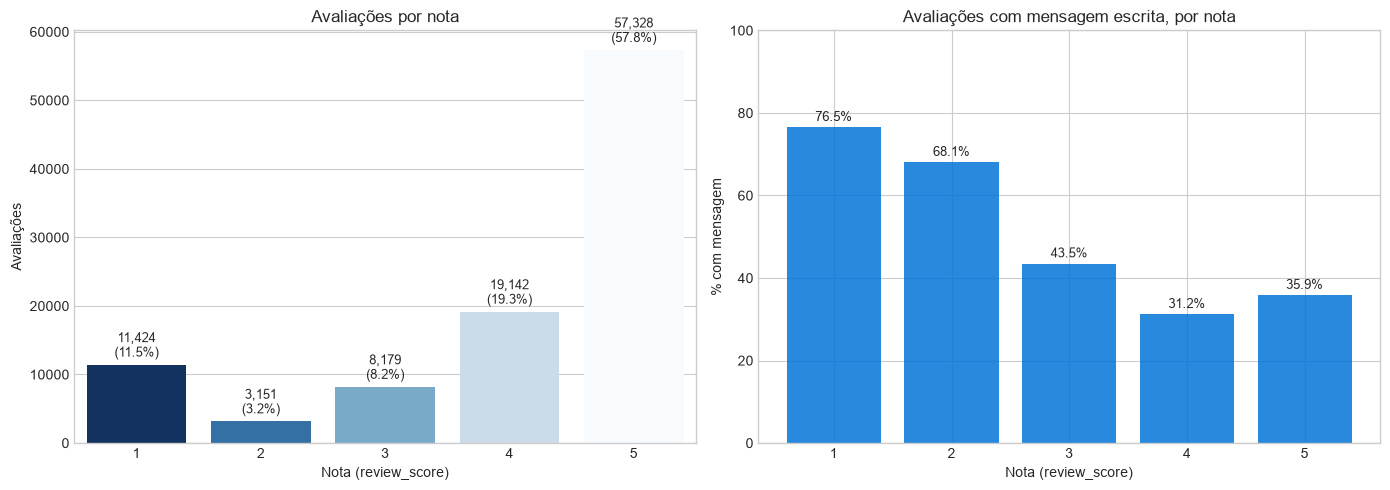

% de avaliações com mensagem por nota:
review_score
1    76.55
2    68.07
3    43.49
4    31.22
5    35.85


In [5]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Quantidade de avaliações por nota
sns.countplot(data=df_reviews, x="review_score", hue="review_score",
              palette="Blues_r", legend=False, ax=axes[0])
axes[0].set_title("Avaliações por nota")
axes[0].set_xlabel("Nota (review_score)")
axes[0].set_ylabel("Avaliações")
for barra in axes[0].patches:
    altura = int(barra.get_height())
    axes[0].annotate(f"{altura:,}\n({altura / total_avaliacoes * 100:.1f}%)",
                     (barra.get_x() + barra.get_width() / 2, altura),
                     ha="center", va="bottom", fontsize=9, xytext=(0, 3), textcoords="offset points")

# Porcentagem de avaliações com mensagem escrita, por nota
pct_mensagem = df_reviews.groupby("review_score")["review_comment_message"].apply(lambda s: s.notna().mean() * 100)
axes[1].bar(pct_mensagem.index.astype(str), pct_mensagem.values, color="#0275d8", alpha=0.85)
axes[1].set_title("Avaliações com mensagem escrita, por nota")
axes[1].set_xlabel("Nota (review_score)")
axes[1].set_ylabel("% com mensagem")
axes[1].set_ylim(0, 100)
for x, y in zip(pct_mensagem.index.astype(str), pct_mensagem.values):
    axes[1].text(x, y + 1.5, f"{y:.1f}%", ha="center", fontsize=9)

plt.tight_layout()
plt.show()

print("% de avaliações com mensagem por nota:")
print(pct_mensagem.round(2).to_string())

**Leitura.** A base é dominada pela nota 5, então qualquer modelo verá muito mais exemplos positivos do que negativos ou neutros. Ao mesmo tempo, quem dá nota baixa escreve com muito mais frequência: cerca de três em cada quatro clientes com nota 1 deixam mensagem, contra pouco mais de um terço dos clientes com nota 5. Por isso, entre as avaliações com texto, os comentários negativos pesam mais do que na base inteira. Essas duas observações justificam a divisão estratificada e os pesos por classe usados nos notebooks 02 e 03.

## 4. Tempo até a resposta e evolução mensal

O campo `review_creation_date` é a data em que a pesquisa foi enviada ao cliente, e `review_answer_timestamp` é o momento em que ele respondeu. A diferença entre os dois mostra quanto tempo o cliente levou para avaliar.

In [6]:
data_envio = pd.to_datetime(df_reviews["review_creation_date"], errors="coerce")
data_resposta = pd.to_datetime(df_reviews["review_answer_timestamp"], errors="coerce")

df_reviews["tempo_resposta_dias"] = (data_resposta - data_envio).dt.total_seconds() / 86400
df_reviews["mes_envio"] = data_envio.dt.to_period("M")

resumo_tempo = df_reviews.groupby("review_score")["tempo_resposta_dias"].agg(
    avaliacoes="count",
    media_dias="mean",
    mediana_dias="median",
    p25_dias=lambda x: np.percentile(x.dropna(), 25),
    p75_dias=lambda x: np.percentile(x.dropna(), 75),
).round(2)
print("Tempo até a resposta, em dias, por nota:")
display(resumo_tempo)

Tempo até a resposta, em dias, por nota:


,avaliacoes,media_dias,mediana_dias,p25_dias,p75_dias
review_score,,,,,
1,11424,3.05,1.55,0.76,3.00
2,3151,3.00,1.70,0.97,3.12
3,8179,2.98,1.76,1.02,3.21
4,19142,3.12,1.79,1.04,3.41
5,57328,3.21,1.66,1.02,3.09


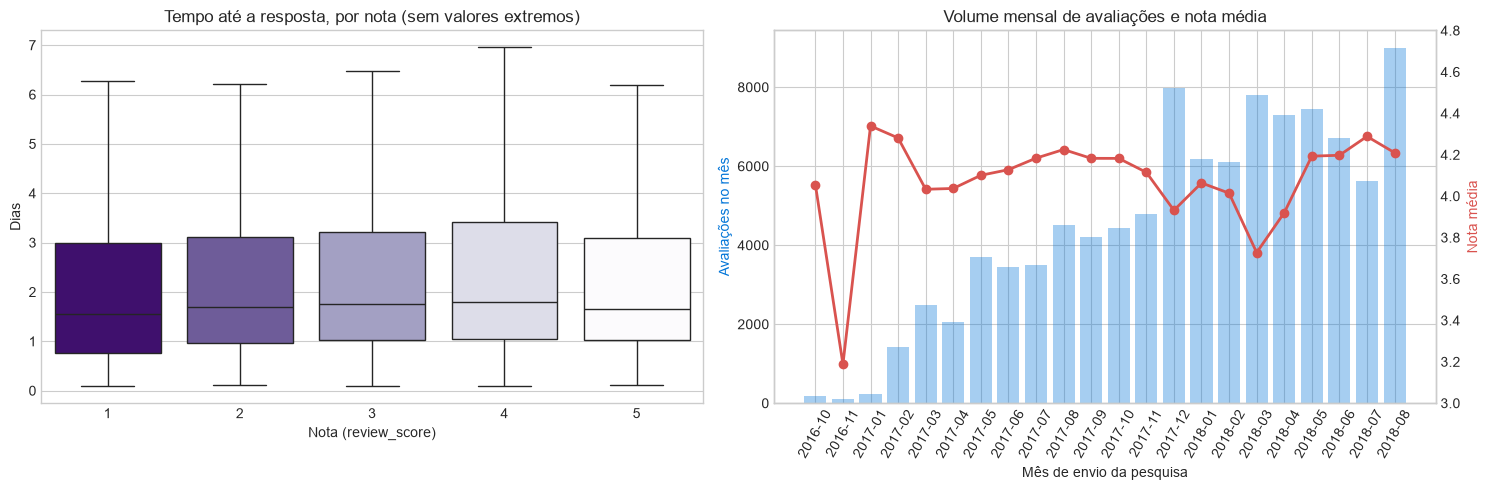

Mediana do tempo de resposta: nota 1 = 1.55 dias, nota 5 = 1.66 dias
Nota média mensal nos meses com 1.000 avaliações ou mais: de 3.73 a 4.29
Menor valor nesses meses: 3.73 em 2018-03 (7,803 avaliações)


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

sns.boxplot(data=df_reviews, x="review_score", y="tempo_resposta_dias", hue="review_score",
            palette="Purples_r", legend=False, showfliers=False, ax=axes[0])
axes[0].set_title("Tempo até a resposta, por nota (sem valores extremos)")
axes[0].set_xlabel("Nota (review_score)")
axes[0].set_ylabel("Dias")

# Meses com poucas avaliações (50 ou menos) são omitidos para não distorcer a média
serie_mensal = (
    df_reviews.groupby("mes_envio")
    .agg(volume=("review_score", "count"), nota_media=("review_score", "mean"))
    .query("volume > 50")
    .reset_index()
)
serie_mensal["mes"] = serie_mensal["mes_envio"].astype(str)

ax_volume = axes[1]
ax_nota = ax_volume.twinx()
ax_volume.bar(serie_mensal["mes"], serie_mensal["volume"], color="#0275d8", alpha=0.35)
ax_nota.plot(serie_mensal["mes"], serie_mensal["nota_media"], color="#d9534f", marker="o", linewidth=2)
ax_volume.set_title("Volume mensal de avaliações e nota média")
ax_volume.set_xlabel("Mês de envio da pesquisa")
ax_volume.set_ylabel("Avaliações no mês", color="#0275d8")
ax_nota.set_ylabel("Nota média", color="#d9534f")
ax_nota.set_ylim(3.0, 4.8)
ax_nota.grid(False)
ax_volume.tick_params(axis="x", rotation=60)

plt.tight_layout()
plt.show()

print(f"Mediana do tempo de resposta: nota 1 = {resumo_tempo.loc[1, 'mediana_dias']} dias, nota 5 = {resumo_tempo.loc[5, 'mediana_dias']} dias")
meses_grandes = serie_mensal[serie_mensal["volume"] >= 1000]
mes_min = meses_grandes.loc[meses_grandes["nota_media"].idxmin()]
print(f"Nota média mensal nos meses com 1.000 avaliações ou mais: de {meses_grandes['nota_media'].min():.2f} a {meses_grandes['nota_media'].max():.2f}")
print(f"Menor valor nesses meses: {mes_min['nota_media']:.2f} em {mes_min['mes']} ({mes_min['volume']:,} avaliações)")

**Leitura.** Os clientes respondem rápido, com mediana perto de um dia e meio em todas as notas, então o tempo de resposta não separa satisfeitos de insatisfeitos. O volume de avaliações cresce ao longo de 2017 e 2018. Os primeiros meses têm poucas avaliações, então suas médias variam muito; a partir daí, a nota média mensal fica perto de 4, com a queda mais visível em março de 2018, um dos meses de maior volume. Como o projeto usa só o arquivo de avaliações, este notebook não mede atraso de entrega: para isso seria preciso a tabela de pedidos da Olist, que está fora do escopo.

## 5. Como os clientes escrevem

A partir daqui olhamos só as avaliações com mensagem (`review_comment_message`). O título é tratado no notebook 02, que junta título e mensagem.

In [8]:
MAPA_SENTIMENTO = {1: "negativo", 2: "negativo", 3: "neutro", 4: "positivo", 5: "positivo"}

df_texto = df_reviews.dropna(subset=["review_comment_message"]).copy()
df_texto["sentimento"] = df_texto["review_score"].map(MAPA_SENTIMENTO)
df_texto["caracteres"] = df_texto["review_comment_message"].str.len()
df_texto["palavras"] = df_texto["review_comment_message"].str.split().str.len()

tamanho = df_texto.groupby("sentimento")[["caracteres", "palavras"]].agg(["mean", "median", "std"]).round(1)
tamanho

caracteres              palavras             
                 mean median   std     mean median   std
sentimento                                              
negativo         99.3   89.0  59.7     17.4   15.0  10.6
neutro           83.3   70.0  58.4     14.6   12.0  10.4
positivo         54.1   43.0  43.9      8.9    7.0   7.6

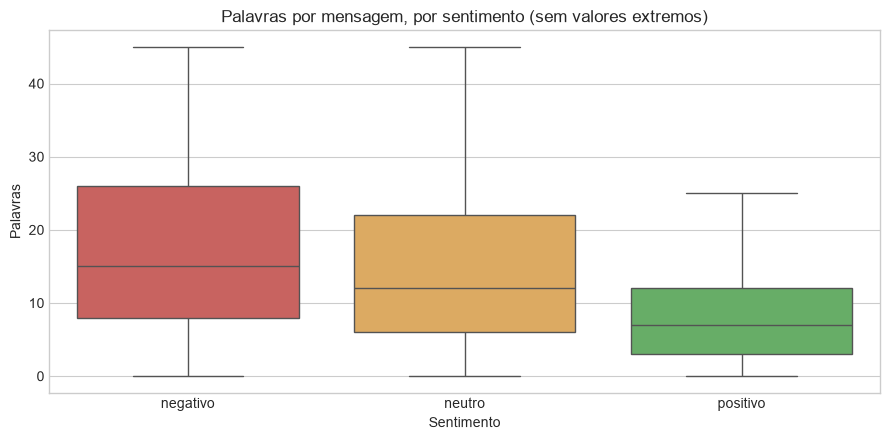

Mediana de palavras por mensagem: negativo: 15, neutro: 12, positivo: 7


In [9]:
plt.figure(figsize=(9, 4.5))
sns.boxplot(data=df_texto, x="sentimento", y="palavras", order=["negativo", "neutro", "positivo"],
            hue="sentimento", palette={"negativo": "#d9534f", "neutro": "#f0ad4e", "positivo": "#5cb85c"},
            legend=False, showfliers=False)
plt.title("Palavras por mensagem, por sentimento (sem valores extremos)")
plt.xlabel("Sentimento")
plt.ylabel("Palavras")
plt.tight_layout()
plt.show()

medianas = df_texto.groupby("sentimento")["palavras"].median()
print("Mediana de palavras por mensagem:", ", ".join(f"{k}: {v:.0f}" for k, v in medianas.items()))

**Leitura.** Mensagens negativas são mais longas: o cliente insatisfeito costuma explicar o que deu errado, enquanto o satisfeito escreve algo curto como "ótimo produto". Isso também indica que o texto negativo tem mais informação sobre o motivo da insatisfação, o que é aproveitado no notebook 05.

### 5.1 Palavras mais frequentes, preservando negações

Para contar palavras, removemos stopwords, que são palavras muito comuns e pouco informativas ("de", "o", "que"). A lista padrão do NLTK, porém, inclui palavras que mudam o sentido da frase, como "não", "nem", "sem" e "mas". Se "não" saísse, "não recebi o produto" viraria "recebi produto". Por isso, antes de filtrar, tiramos da lista "não", "nem", "nunca", "sem", "pouco", "muito", "mas", "porém" e "nada".

Esta tokenização é só para a contagem exploratória. Os modelos usam a normalização de `src/preparacao.py` e o TF-IDF do notebook 03, sem remoção de stopwords.

In [10]:
import nltk
from nltk.corpus import stopwords

try:
    stopwords_pt = set(stopwords.words("portuguese"))
except LookupError:
    nltk.download("stopwords")
    stopwords_pt = set(stopwords.words("portuguese"))

palavras_mantidas = {"não", "nem", "nunca", "sem", "pouco", "muito", "mas", "porém", "nada"}
stopwords_ajustadas = stopwords_pt - palavras_mantidas

def tokenizar(texto: str) -> list[str]:
    """Minúsculas, remove URLs, números e pontuação; descarta stopwords e palavras com até 2 letras."""
    t = unicodedata.normalize("NFKC", str(texto)).lower()
    t = re.sub(r"https?://\S+|www\.\S+", " ", t)
    t = re.sub(r"\d+", " ", t)
    t = re.sub(r"[^\w\sáàâãéèêíïóôõöúçñ]", " ", t)
    return [p for p in t.split() if len(p) > 2 and p not in stopwords_ajustadas]

df_texto["tokens"] = df_texto["review_comment_message"].apply(tokenizar)
df_texto[["review_comment_message", "tokens", "sentimento"]].head(3)

,review_comment_message,tokens,sentimento
3,Recebi bem antes do prazo estipulado.,"[recebi, bem, antes, prazo, estipulado]",positivo
4,Parabéns lojas lannister adorei comprar pela I...,"[parabéns, lojas, lannister, adorei, comprar, ...",positivo
9,aparelho eficiente. no site a marca do aparelh...,"[aparelho, eficiente, site, marca, aparelho, i...",positivo


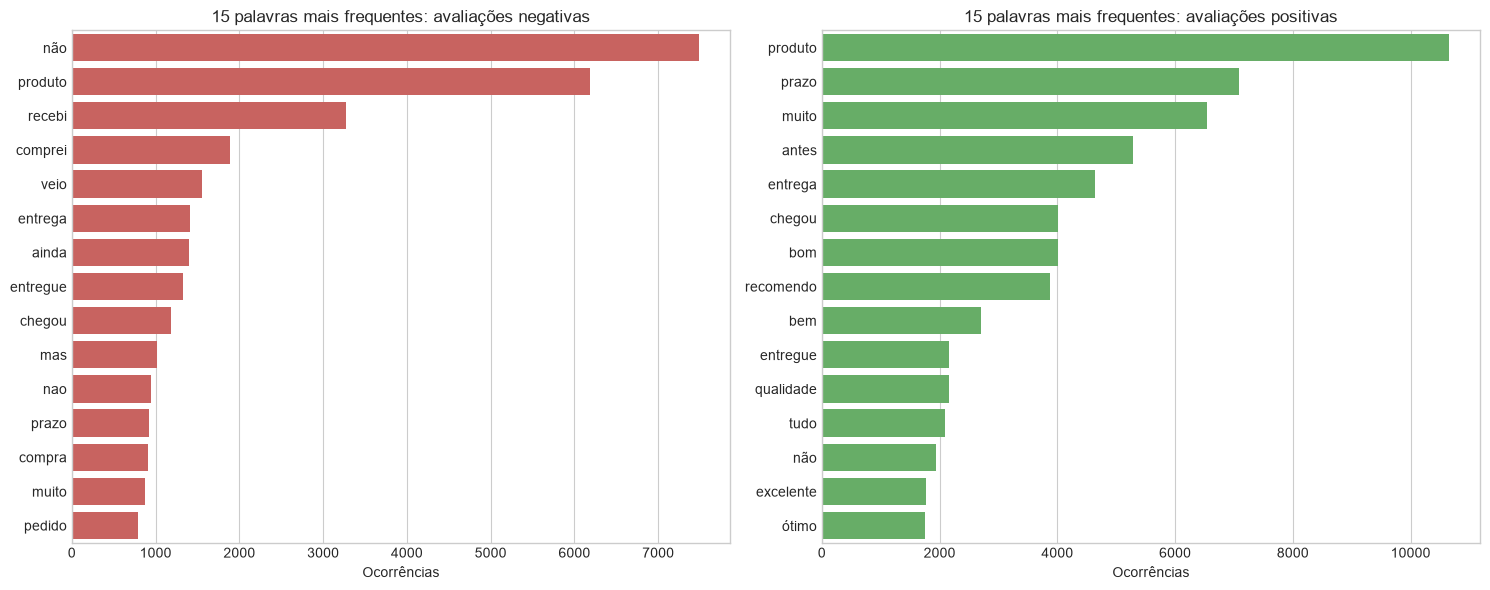

In [11]:
def mais_frequentes(sentimento: str, n: int = 15) -> pd.DataFrame:
    tokens = [t for lista in df_texto.loc[df_texto["sentimento"] == sentimento, "tokens"] for t in lista]
    return pd.DataFrame(Counter(tokens).most_common(n), columns=["palavra", "ocorrencias"])

top_negativo = mais_frequentes("negativo")
top_positivo = mais_frequentes("positivo")

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
sns.barplot(data=top_negativo, x="ocorrencias", y="palavra", color="#d9534f", ax=axes[0])
axes[0].set_title("15 palavras mais frequentes: avaliações negativas")
sns.barplot(data=top_positivo, x="ocorrencias", y="palavra", color="#5cb85c", ax=axes[1])
axes[1].set_title("15 palavras mais frequentes: avaliações positivas")
for ax in axes:
    ax.set_xlabel("Ocorrências")
    ax.set_ylabel("")
plt.tight_layout()
plt.show()

**Leitura.** Nas avaliações negativas aparecem palavras ligadas a entrega e recebimento ("não", "produto", "recebi", "entrega", "prazo"). Nas positivas predominam elogios e confirmações de prazo. A frequência de uma palavra não diz, sozinha, qual é o motivo da reclamação; o notebook 05 investiga os temas com modelagem de tópicos.

## 6. O que levamos para as próximas etapas

1. **Classes desbalanceadas.** A maioria das notas é 4 ou 5. A divisão entre treino e teste precisa ser estratificada, e o modelo precisa de algum ajuste para as classes menores (notebook 03 usa `class_weight="balanced"`).
2. **Texto é opcional.** Cerca de 59% das avaliações não têm mensagem. Só as avaliações com texto entram nos modelos, o que muda a proporção entre as classes.
3. **Negações importam.** Palavras como "não" e "nunca" não podem ser removidas na preparação.
4. **Limite do escopo.** O arquivo de avaliações não traz datas de entrega; relações entre atraso e nota não podem ser medidas aqui.

Sequência: notebook 02 (preparação, Lucas), notebook 03 (comparação de modelos, Jaqueline), notebook 04 (avaliação e métricas, Kayo) e notebook 05 (temas de insatisfação, equipe).